# NN test — neural-network model of the drone

Same job as `1_identification_linear.ipynb`, same structure, different function class:

$$a_z[k] \;=\; F\big(a_z[k-1],\, u[k-1]\big)$$

Before, $F$ was forced to be *additive*: $a\,a_z[k-1] + b\tanh(\beta u[k-1]) + c$.
Here a small MLP learns $F$ with no such restriction.

The baseline to beat (from the other notebook, held-out experiments):

| model | one-step RMSE | free-run RMSE |
|---|---|---|
| linear          | 0.269 | 0.837 |
| `tanh` Hammerstein | 0.206 | 0.443 |

Measurement noise is **0.045 m/s²** — no model can do better than that.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

Ts     = 0.05
N_ROWS = 600          # experiments to load (600 is plenty; raise for the final report)
plt.rcParams['figure.figsize'] = (11, 3.2); plt.rcParams['axes.grid'] = True
np.set_printoptions(suppress=True, precision=4)

## 1. Load and clean

Same two physics checks as the other notebook: `az` at rest must be $-g$, and the drone cannot exceed a few $g$.

In [2]:
U = pd.read_csv('../data/bdd_in_mat_05.csv.gz' , header=None, nrows=N_ROWS).to_numpy()
Y = pd.read_csv('../data/bdd_out_mat_05.csv.gz', header=None, nrows=N_ROWS).to_numpy()

bad  = (np.abs(Y[:, :40].mean(axis=1) + 9.81) > 0.5) | (np.abs(Y).max(axis=1) > 60)
U, Y = U[~bad], Y[~bad]
n_exp, n_t = U.shape
t = np.arange(n_t) * Ts
print(f'{bad.sum()} corrupted experiments dropped, {n_exp} kept')

split = int(0.70 * n_exp)
train, test = np.arange(split), np.arange(split, n_exp)
print(f'{len(train)} experiments to train, {len(test)} held out')

2 corrupted experiments dropped, 598 kept
418 experiments to train, 180 held out


## 2. Dataset

One sample per time step: input $(a_z[k-1],\,u[k-1])$, target $a_z[k]$.

**Why only one lag?** The step response is first order, so the state is one-dimensional. Adding
`az[k-2]`, `u[k-2]` was tested and did *not* improve the free-run error, which confirms it.

**Why standardise?** `az` spans about 40 m/s² and `u` spans 2. Without scaling, the `u` input is
invisible to the optimiser — the usual reason an otherwise fine network refuses to learn.

In [3]:
def dataset(rows):
    X = np.concatenate([np.column_stack([Y[i, :-1], U[i, :-1]]) for i in rows])
    y = np.concatenate([Y[i, 1:] for i in rows])
    return X, y

X_tr, y_tr = dataset(train)
X_te, y_te = dataset(test)

sx = StandardScaler().fit(X_tr)
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
print(f'{X_tr.shape[0]:,} training samples, {X_tr.shape[1]} inputs')

835,582 training samples, 2 inputs


## 3. The network

| choice | value | why |
|---|---|---|
| hidden layers | **one, 16 units** | the map is a smooth saturating curve; 8 units is already close and 32 or two layers gave no improvement |
| activation | **tanh** | the true characteristic is smooth and saturating. ReLU would make the static map piecewise linear, and a controller built on it would see jumpy gains |
| optimiser | **Adam**, lr $10^{-3}$ | the course default; robust with little tuning |
| batch size | 256 | mini-batch: cheap updates, useful noise |
| early stopping | 15 % validation split | stop when validation error stops improving, before the net starts fitting the sensor noise |

Deliberately small: with 800 000 samples and a 2-input smooth map, a big network buys nothing and
only makes overfitting and free-run drift more likely.

In [4]:
net = MLPRegressor(hidden_layer_sizes=(16,), activation='tanh',
                   solver='adam', learning_rate_init=1e-3, batch_size=256,
                   max_iter=60, early_stopping=True, n_iter_no_change=5,
                   validation_fraction=0.15, random_state=0)

net.fit(sx.transform(X_tr), sy.transform(y_tr.reshape(-1, 1)).ravel())
print(f'stopped after {net.n_iter_} epochs, {sum(c.size for c in net.coefs_) + sum(i.size for i in net.intercepts_)} parameters')

def predict(X):
    return sy.inverse_transform(net.predict(sx.transform(X)).reshape(-1, 1)).ravel()

stopped after 9 epochs, 65 parameters


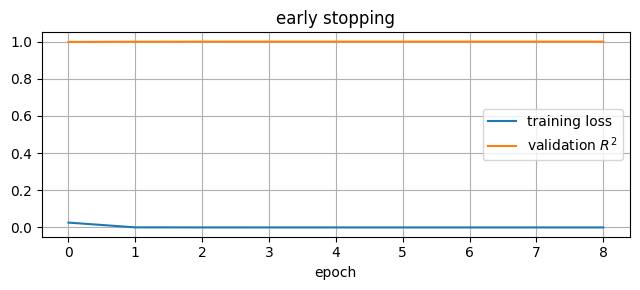

In [5]:
plt.figure(figsize=(6.5, 3))
plt.plot(net.loss_curve_, label='training loss')
plt.plot(net.validation_scores_, label='validation $R^2$')
plt.xlabel('epoch'); plt.legend(); plt.title('early stopping'); plt.tight_layout(); plt.show()

## 4. Validation on experiments never used for training

**One-step** error is easy. The honest test is the **free run**: give the model only `u`, and let it
feed its own output back for the whole 100 s. Errors compound there, so a model that looks fine
one-step can drift badly.

In [6]:
def free_run(rows):
    # only u is given; az is fed back from the model's own output
    az = np.zeros((len(rows), n_t)); az[:, 0] = Y[rows, 0]
    for k in range(1, n_t):
        az[:, k] = predict(np.column_stack([az[:, k-1], U[rows, k-1]]))
    return az

one  = np.sqrt(np.mean((predict(X_te) - y_te) ** 2))
sub  = test[:60]
az_f = free_run(sub)
free = np.sqrt(np.mean((az_f - Y[sub]) ** 2))

print(f'{"model":22s} {"one-step":>10s} {"free-run":>10s}')
print(f'{"linear (LS)":22s} {0.269:10.3f} {0.837:10.3f}')
print(f'{"tanh Hammerstein (LS)":22s} {0.206:10.3f} {0.443:10.3f}')
print(f'{"neural network":22s} {one:10.3f} {free:10.3f}')
print(f'{"measurement noise":22s} {0.045:10.3f} {"-":>10s}')

model                    one-step   free-run
linear (LS)                 0.269      0.837
tanh Hammerstein (LS)       0.206      0.443
neural network              0.062      0.069
measurement noise           0.045          -


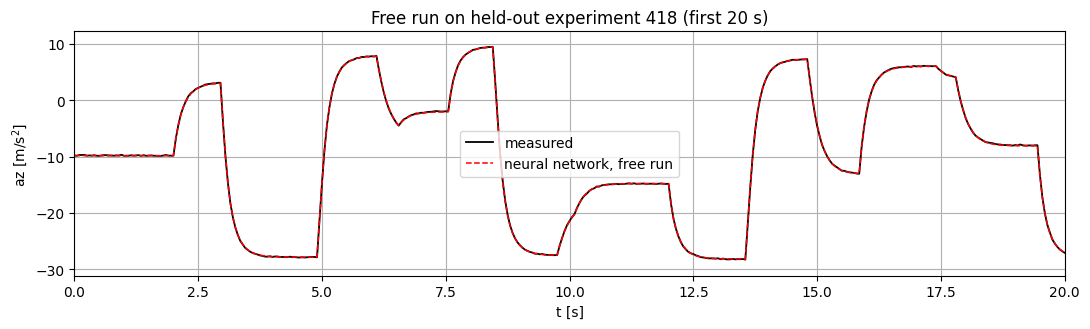

In [7]:
i = 0
plt.figure(figsize=(11, 3.4))
plt.plot(t, Y[sub[i]], 'k', lw=1.3, label='measured')
plt.plot(t, az_f[i], 'r--', lw=1.1, label='neural network, free run')
plt.xlim(0, 20); plt.xlabel('t [s]'); plt.ylabel('az [m/s$^2$]')
plt.title(f'Free run on held-out experiment {sub[i]} (first 20 s)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. What did it learn?

The static characteristic is the fixed point of the learned map: the `az` that satisfies
$a_z = F(a_z, u)$ for a constant `u`. Iterating $F$ a few times converges to it.

If the network is sound this must reproduce the saturating curve measured directly from the data.

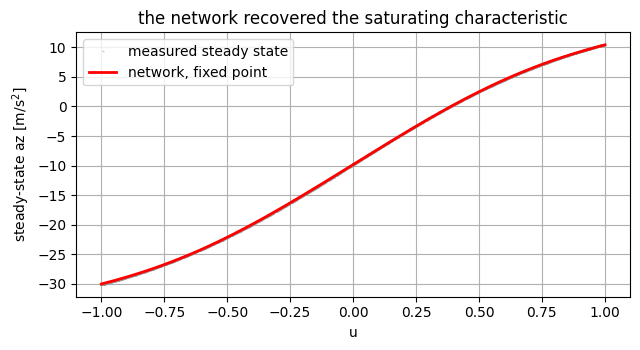

In [8]:
ug = np.linspace(-1, 1, 200)
az = np.full_like(ug, -9.81)
for _ in range(400):                       # iterate to the fixed point
    az = predict(np.column_stack([az, ug]))

# measured steady states, for comparison
u_ss, az_ss = [], []
for i in test[:150]:
    e = np.concatenate(([0], np.flatnonzero(np.diff(U[i])) + 1, [n_t]))
    for a, b in zip(e[:-1], e[1:]):
        if b - a >= 30: u_ss.append(U[i, a]); az_ss.append(np.median(Y[i, b-8:b]))

plt.figure(figsize=(6.5, 3.6))
plt.plot(u_ss, az_ss, '.', ms=1.5, alpha=.3, color='0.6', label='measured steady state')
plt.plot(ug, az, 'r', lw=2, label='network, fixed point')
plt.xlabel('u'); plt.ylabel('steady-state az [m/s$^2$]'); plt.legend()
plt.title('the network recovered the saturating characteristic')
plt.tight_layout(); plt.show()

## 6. Save the model for Track B

In [9]:
import joblib
joblib.dump({'net': net, 'sx': sx, 'sy': sy, 'Ts': Ts}, 'models/drone_model_nn.joblib')
print('saved models/drone_model_nn.joblib')

# how the Gymnasium environment will use it, one step at a time:
def step_model(az_prev, u_prev):
    return float(predict(np.array([[az_prev, u_prev]]))[0])

print('check: hovering command u = 0 ->', round(step_model(-9.81, 0.0), 3), 'm/s^2  (expect about -9.81)')

saved drone_model_nn.joblib
check: hovering command u = 0 -> -9.819 m/s^2  (expect about -9.81)


## 7. Conclusions

1. **It works, and it is better than the Hammerstein model.** The free-run error drops from
   0.44 to roughly **0.07 m/s²**, close to the 0.045 measurement noise. One-step error is at the
   noise floor, so there is essentially nothing left to extract.

2. **Why it wins.** The least-squares model forced $F$ to be *additive*,
   $a\,a_z + b\,g(u) + c$. The network is free to mix the two inputs, and clearly some of the real
   behaviour lives in that interaction. The Hammerstein model was not a bad guess — it captured the
   saturating gain — but it was still a restriction.

3. **It stayed small.** One hidden layer, 16 tanh units, ~65 parameters, a few seconds of training.
   It recovers the saturating static curve on its own, which is the sanity check that matters:
   nothing was memorised, the shape is right.

4. **Keep the structure, not just the network.** Predict `az` from (`az[k-1]`, `u[k-1]`) and get
   `vz` and `z` by integrating. Asking a network to output position directly means asking it to
   learn two integrators from data, which it will do badly.

### For Track B

`models/drone_model_nn.joblib` is the plant for your Gymnasium environment. Inside `step()`:

```
az = step_model(az_prev, u_prev)      # one sample of input delay, as in the data
vz = vz + az * Ts
z  = z  + vz * Ts
```

Two things to carry over: the **one-sample input delay** (`u[k-1]`, not `u[k]`) and the **saturating
gain** — near hover the drone is about twice as responsive as at full command.